In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

P = '../02_Data/processed/'
listings = pd.read_csv(P + 'listings_clean.csv', low_memory=False)
calendar = pd.read_csv(P + 'calendar_clean.csv', low_memory=False, parse_dates=['date'])

# Distribution
print("DISTRIBUTION")
print(listings['minimum_nights'].describe(percentiles=[.5,.75,.9,.95,.99]).round(1))

# By room type
print("\nBY ROOM TYPE")
print(listings.groupby('room_type')['minimum_nights'].agg(
    ['count','median', lambda s: round((s>7).mean()*100,1)]
).rename(columns={'<lambda_0>':'%_over_7'}))

# Long-term segment
lt = (listings['minimum_nights'] > 30).sum()
print(f"\n=== LONG-TERM (>30 nights) ===")
print(f"Listings: {lt:,} ({lt/len(listings)*100:.1f}%)")

DISTRIBUTION
count    15292.0
mean        14.1
std         21.4
min          1.0
50%          2.0
75%         31.0
90%         32.0
95%         32.0
99%         45.0
max        900.0
Name: minimum_nights, dtype: float64

BY ROOM TYPE
                 count  median  %_over_7
room_type                               
Entire home/apt  10843     2.0      37.5
Hotel room          68     1.0       0.0
Private room      4262     3.0      45.4
Shared room        119     1.0      10.1

=== LONG-TERM (>30 nights) ===
Listings: 5,527 (36.1%)


In [5]:
# Price relationship
print("PRICE vs MIN NIGHTS")
print(f"Pearson: {listings[['minimum_nights','price']].dropna().corr().iloc[0,1]:.3f}")

# Availability relationship
avail = calendar.groupby('listing_id')['available'].mean().mul(100).round(1)
df = listings.merge(avail.rename('avail_pct'), left_on='id', right_index=True)
print(f"\nAVAILABILITY vs MIN NIGHTS")
print(f"Pearson: {df[['minimum_nights','avail_pct']].dropna().corr().iloc[0,1]:.3f}")
print(f"\nMedian availability by bucket:")
print(df.groupby(pd.cut(df['minimum_nights'], [0,1,3,7,30,365,np.inf]))['avail_pct'].median().round(0))

PRICE vs MIN NIGHTS
Pearson: -0.328

AVAILABILITY vs MIN NIGHTS
Pearson: 0.032

Median availability by bucket:
minimum_nights
(0.0, 1.0]       66.0
(1.0, 3.0]       62.0
(3.0, 7.0]       44.0
(7.0, 30.0]      90.0
(30.0, 365.0]    68.0
(365.0, inf]      2.0
Name: avail_pct, dtype: float64


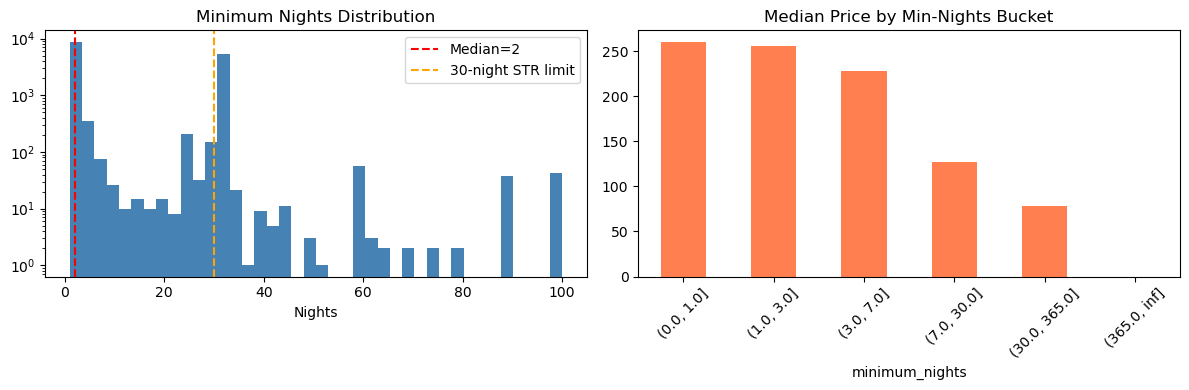

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))

# Distribution
ax[0].hist(listings['minimum_nights'].clip(upper=100), bins=40, color='steelblue')
ax[0].set_yscale('log')
ax[0].set_title('Minimum Nights Distribution')
ax[0].set_xlabel('Nights')
ax[0].axvline(2, color='red', ls='--', label='Median=2')
ax[0].axvline(30, color='orange', ls='--', label='30-night STR limit')
ax[0].legend()

# Median price by bucket
listings.groupby(pd.cut(listings['minimum_nights'], [0,1,3,7,30,365,np.inf]))['price'].median().plot(
    kind='bar', ax=ax[1], color='coral')
ax[1].set_title('Median Price by Min-Nights Bucket')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout(); plt.show()